# D · Anomaly detection — what needs attention?

Three layers, each answering a different question for a facilities manager:

| Layer | Question | Method |
|---|---|---|
| Data quality | Can I trust the reading? | point-day health score: offline, flatline, out-of-range, spikes (`health.py`) |
| Rules | Is equipment running when it should not? | after-hours AC above the floor's own night baseline; always-on and dead units |
| Statistical | Is the floor using more than the weather and calendar explain? | robust z of cross-fitted TOWT residuals (> 3.5 for ≥ 2 h); CUSUM on daily residuals for drift |

There are no labels, so the detector is **validated against known events**: weekend AC programmes found
independently in the F3 notebook should be caught; holidays and closures should *not* be flagged more than
ordinary workdays (the baseline knows the calendar); and the flagged share must stay small enough for a usable
alarm list.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
from sbanalytics import baseline as B, anomaly as AN, health as HL, config as C

In [2]:
h = D.load_hourly(None)
fh = B.floor_hourly(h)
fd = B.floor_daily(fh)
OFFICE = [2, 3, 4, 5, 6, 7]     # F1 has no AC schedule (eda/00 §5): excluded from schedule-based measures
TARIFF = R.conv('tariff_thb')    # THB/kWh, declared assumption (registry.CONVENTIONS)
print(f'Tariff assumption: {TARIFF} THB/kWh')

Tariff assumption: 4.2 THB/kWh


## 1 · Data-quality layer

In [3]:
S = HL.score_point_days(D.load_health(None))
S = S[~S.in_blackout]
flags = ["flag_offline", "flag_partial", "flag_flatline", "flag_zero_stuck", "flag_range", "flag_spike"]
dq = S.groupby("floor")[flags].mean().mul(100).round(2)
dq["mean health score"] = S.groupby("floor").health.mean().round(1)
dq.columns = [c.replace("flag_", "% point-days ") if c.startswith("flag_") else c for c in dq.columns]
dq

,% point-days offline,% point-days partial,% point-days flatline,% point-days zero_stuck,% point-days range,% point-days spike,mean health score
floor,,,,,,,
1,0.44,1.49,0.07,0.00,0.54,0.12,99.0
2,1.85,2.79,9.80,16.60,0.00,0.17,93.0
3,2.65,4.53,3.43,19.28,0.00,0.00,94.7
4,4.51,6.30,1.20,14.37,0.00,0.00,93.4
5,4.27,6.63,4.27,18.86,0.23,0.23,92.3
6,19.54,4.39,2.75,13.66,0.00,0.46,78.1
7,0.50,4.45,12.37,14.43,0.00,0.03,92.8


In [4]:
stuck = HL.stuck_summary(D.load_health(None))
stuck = stuck[stuck.flat_day_share > 20]
stuck.head(15)

,floor,zone,channel,column,role,days,flat_days,longest_min,median_distinct,flat_day_share
27,2,z2,ac,z2_AC6(kW),primary,549,527,554,89.0,95.99
141,6,z2,light,z2_Light(kW),primary,549,466,1784,102.0,84.88
178,7,z3,light,z3_Light(kW),primary,549,444,2345,16.0,80.87
165,7,z1,ac,z1_AC3(kW),residual,549,360,3631,34.0,65.57
38,2,z3,plug,z3_Plug(kW),primary,549,355,790,29.0,64.66
121,5,z3,plug,z3_Plug(kW),suspect_constant,549,342,1218,7.0,62.30
179,7,z3,plug,z3_Plug(kW),primary,549,324,1089,10.0,59.02
44,2,z4,plug,z4_Plug(kW),suspect_constant,549,319,1166,2.0,58.11
175,7,z2,plug,z2_Plug(kW),primary,549,266,2425,64.0,48.45
164,7,z1,ac,z1_AC2(kW),residual,549,235,5571,26.0,42.81


## 2 · Rule layer

### After-hours AC
AC energy outside each floor's measured schedule (weekends, holidays, closures, and hours outside the schedule on workdays) above max(0.5 kWh, night median + 3.5 MAD). Office floors only.

In [5]:
ah = AN.after_hours_ac(fh[fh.floor.isin(OFFICE)])
days = fd[fd.ok].groupby("floor").size()
summ = ah.groupby("floor").agg(event_days=("day", "size"), excess_kwh=("excess_kwh", "sum"))
summ["excess_kwh_per_year"] = summ.excess_kwh / days.loc[summ.index] * 365
summ["thb_per_year"] = summ.excess_kwh_per_year * TARIFF
summ["share_on_weekend_or_holiday"] = ah.assign(nw=ah.day_type.isin(["weekend", "holiday", "closure"])).groupby("floor").nw.mean()
summ.round(2)

,event_days,excess_kwh,excess_kwh_per_year,thb_per_year,share_on_weekend_or_holiday
floor,,,,,
2,180,13975.87,9679.68,40654.66,0.20
3,62,1918.10,1473.91,6190.42,0.69
4,38,3417.71,2398.97,10075.68,0.89
5,55,1083.21,760.33,3193.38,0.42
6,63,954.99,730.76,3069.18,0.65
7,124,24285.86,16820.38,70645.60,0.47


In [6]:
ah.sort_values("excess_kwh", ascending=False).head(10).round(1)

,floor,day,hours,day_type,first_hour,last_hour,ac_kwh,excess_kwh,threshold_kwh
507,7,2019-07-27,11,weekend,7,17,759.3,759.2,0.5
510,7,2019-08-18,9,weekend,8,16,710.0,709.9,0.5
506,7,2019-07-20,9,weekend,8,16,663.3,663.2,0.5
477,7,2019-05-04,11,weekend,7,17,647.3,647.2,0.5
503,7,2019-06-29,9,weekend,8,16,615.7,615.6,0.5
508,7,2019-08-03,9,weekend,9,17,605.6,605.5,0.5
505,7,2019-07-13,10,weekend,7,16,549.0,548.9,0.5
499,7,2019-06-01,10,weekend,7,16,526.5,526.4,0.5
5,2,2018-07-07,10,weekend,7,16,556.7,491.0,11.1
513,7,2019-08-31,10,weekend,7,16,468.3,468.2,0.5


### Always-on and dead AC units

In [7]:
units = AN.unit_status(D.load_hourly_points())
units[units.status.isin(["always-on", "dead"])].round(3)

,floor,zone,column,role,kwh,hours,on_share,night_on_share,floor_share,status
0,1,z2,z2_AC1(kW),primary,368478.88,13152,0.78,0.99,0.85,always-on
5,2,z2,z2_AC1(kW),primary,77045.85,12677,0.94,1.00,0.27,always-on
15,2,z2,z2_AC6(kW),primary,7710.68,13165,0.79,1.00,0.03,always-on
7,2,z2,z2_AC11(kW),dead,0.00,13165,0.00,0.00,0.00,dead
48,7,z1,z1_AC1(kW),dead,0.00,13142,0.00,0.00,0.00,dead


## 3 · Statistical layer

Residuals are **cross-fitted by quarter**: each quarter is predicted by a TOWT model trained on the other quarters, so an anomaly is never absorbed into its own baseline. The residual scale is the larger of 1.4826·MAD and 5 % of the floor's median occupied-hour load (a materiality floor — without it, near-zero off-hours variance makes every 1 kWh blip an outlier).

In [8]:
r = AN.crossfit_residuals(fh, "total_kwh")
ev = AN.flag_events(r)
share = (r.z.abs() > AN.ROBUST_Z).groupby(r.floor).mean().rename("share of hours beyond |z| 3.5")
counts = ev.groupby(["floor", "direction"]).size().unstack(fill_value=0)
pd.concat([share, counts], axis=1).style.format({"share of hours beyond |z| 3.5": "{:.1%}"})

,share of hours beyond |z| 3.5,deficit,excess
floor,,,
1,0.4%,0,9
2,7.7%,73,126
3,0.8%,1,22
4,1.1%,0,36
5,0.4%,3,14
6,0.5%,1,14
7,5.3%,51,109


In [9]:
ev[ev.direction == "excess"].sort_values("excess_kwh", ascending=False).head(12).round(1)

,floor,start,end,hours,direction,excess_kwh,peak_z,day_type,occupied_share
0,1,2018-07-02 08:00:00,2018-07-02 17:00:00,9,excess,870.9,5.1,workday,1.0
412,7,2019-05-21 17:00:00,2019-05-22 05:00:00,12,excess,697.8,11.0,workday,0.0
427,7,2019-07-27 08:00:00,2019-07-27 17:00:00,9,excess,660.6,16.2,weekend,0.0
399,7,2019-05-04 07:00:00,2019-05-04 18:00:00,11,excess,649.3,14.1,weekend,0.0
4,1,2018-08-17 01:00:00,2018-08-17 06:00:00,5,excess,558.0,4.1,workday,0.0
2,1,2018-08-09 18:00:00,2018-08-09 23:00:00,5,excess,555.4,4.3,workday,0.0
12,2,2018-07-07 07:00:00,2018-07-07 17:00:00,10,excess,521.7,16.5,weekend,0.0
23,2,2018-07-21 07:00:00,2018-07-21 17:00:00,10,excess,490.9,14.0,weekend,0.0
428,7,2019-08-03 10:00:00,2019-08-03 17:00:00,7,excess,482.7,13.8,weekend,0.0
420,7,2019-06-01 07:00:00,2019-06-01 17:00:00,10,excess,468.9,11.0,weekend,0.0


### Drift: CUSUM on daily residuals

A point test misses a slow creep (e.g. equipment left on a little more each week). CUSUM accumulates small standardised daily deviations and alarms when the sum exceeds 5 robust standard deviations (slack 0.5).

In [10]:
daily_resid = r.groupby(["floor", r.ts.dt.normalize()]).resid.sum()
cus = pd.concat({f: AN.cusum(s.droplevel(0)) for f, s in daily_resid.groupby(level=0)}, names=["floor"]).reset_index(level=0)
alarms = cus[cus.alarm != ""]
alarms.groupby(["floor", "alarm"]).size().unstack(fill_value=0)

alarm,down,up
floor,,
1,7,14
2,5,20
3,7,24
4,7,27
5,12,23
6,5,14
7,8,33


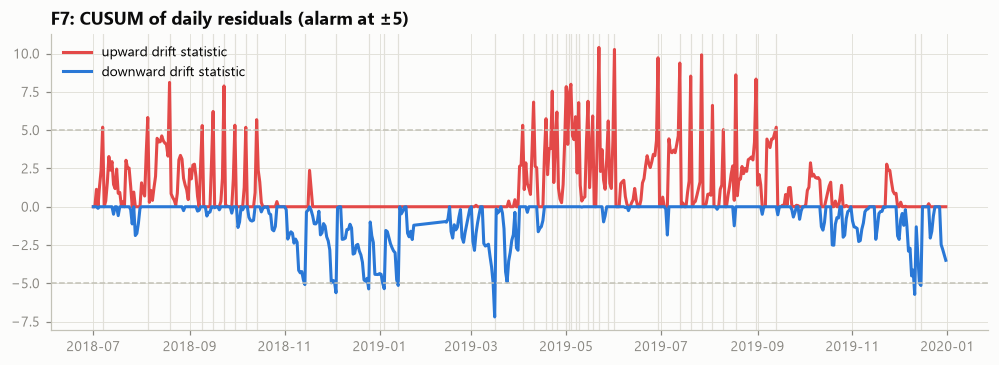

In [11]:
FLOOR = 7
c = cus[cus.floor == FLOOR]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(c.day, c.cusum_hi, color=viz.CATEGORICAL[7], label="upward drift statistic")
ax.plot(c.day, c.cusum_lo, color=viz.CATEGORICAL[0], label="downward drift statistic")
ax.axhline(AN.CUSUM_H, color=viz.AXIS, lw=1, ls="--"); ax.axhline(-AN.CUSUM_H, color=viz.AXIS, lw=1, ls="--")
for _, a in c[c.alarm != ""].iterrows():
    ax.axvline(a.day, color=viz.GRID, lw=0.8, zorder=0)
ax.set_title(f"F{FLOOR}: CUSUM of daily residuals (alarm at ±{AN.CUSUM_H:g})"); ax.legend(loc="upper left")

## 4 · Validation against known events

In [12]:
def caught(frame, day_col, floor, dates):
    d = frame[frame.floor == floor][day_col].dt.strftime("%Y-%m-%d")
    return [x for x in dates if (d == x).any()]

known = AN.F3_KNOWN_WEEKEND_RUNS
v_stat = caught(ev[ev.direction == "excess"], "start", 3, known)
v_rule = caught(ah, "day", 3, known)
print(f"F3 weekend AC runs found by the F3 notebook: {len(known)}")
print(f"  caught by statistical layer: {len(v_stat)}/{len(known)}  {v_stat}")
print(f"  caught by rule layer:        {len(v_rule)}/{len(known)}  {v_rule}")

rate = r.assign(flag=r.z > AN.ROBUST_Z).groupby("day_type").flag.mean()
print("\nShare of hours flagged as excess, by day type (holidays should not stand out):")
print(rate.map("{:.1%}".format).to_string())
office_share = (r[r.floor.isin([3, 4, 5, 6])].z.abs() > AN.ROBUST_Z).mean()
print(f"\nFlagged share on F3–F6: {office_share:.1%} of hours (F3 notebook's earlier 6×MAD rule: 25.9%; its refined rule: 2.3%)")

F3 weekend AC runs found by the F3 notebook: 5
  caught by statistical layer: 5/5  ['2018-09-08', '2019-04-27', '2019-09-14', '2019-09-15', '2019-09-21']
  caught by rule layer:        5/5  ['2018-09-08', '2019-04-27', '2019-09-14', '2019-09-15', '2019-09-21']

Share of hours flagged as excess, by day type (holidays should not stand out):
day_type
closure           2.3%
holiday           1.5%
holiday_worked    1.5%
weekend           2.9%
workday           1.2%

Flagged share on F3–F6: 0.7% of hours (F3 notebook's earlier 6×MAD rule: 25.9%; its refined rule: 2.3%)


F2 and F7 flag more hours than the other floors. Their excess events are dominated by full AC programmes on
weekends (see the top-events table) — that is behaviour to act on, not detector noise.

## 5 · Unified fault register

One table, all floors, ranked by cost. Priority: **high** ≥ 1,000 THB per event-year, **medium** ≥ 200 THB, else **low**; data-quality items are **medium** because every other number depends on them.

In [13]:
reg = []
for _, e in ah.iterrows():
    reg.append({"floor": e.floor, "zone": "floor", "type": "after-hours AC", "layer": "rule",
                "start": e.day + pd.Timedelta(hours=e.first_hour), "end": e.day + pd.Timedelta(hours=e.last_hour + 1),
                "excess_kwh": e.excess_kwh, "detail": f"{e.hours} h above {e.threshold_kwh:.1f} kWh/h on a {e.day_type}"})
for _, e in ev[ev.direction == "excess"].iterrows():
    reg.append({"floor": e.floor, "zone": "floor", "type": "consumption above baseline", "layer": "statistical",
                "start": e.start, "end": e.end, "excess_kwh": e.excess_kwh,
                "detail": f"{e.hours} h, peak z {e.peak_z:.1f}, {e.day_type}"})
for _, a in alarms[alarms.alarm == "up"].iterrows():
    reg.append({"floor": a.floor, "zone": "floor", "type": "upward drift (CUSUM)", "layer": "statistical",
                "start": a.day, "end": a.day + pd.Timedelta(days=1), "excess_kwh": np.nan, "detail": "sustained daily excess"})
for _, u in units[units.status.isin(["always-on", "dead"])].iterrows():
    reg.append({"floor": u.floor, "zone": u.zone, "type": f"AC unit {u.status}", "layer": "rule",
                "start": fh.ts.min(), "end": fh.ts.max(), "excess_kwh": np.nan,
                "detail": f"{u.column}: runs {u.night_on_share:.0%} of night hours, {u.kwh:,.0f} kWh over record"})
for _, s in stuck.iterrows():
    reg.append({"floor": s.floor if "floor" in s else np.nan, "zone": s.zone, "type": "frozen meter", "layer": "data quality",
                "start": fh.ts.min(), "end": fh.ts.max(), "excess_kwh": np.nan,
                "detail": f"{s.column}: flat on {s.flat_day_share:.0f}% of days"})
reg = pd.DataFrame(reg)
reg["thb"] = reg.excess_kwh * TARIFF
reg["priority"] = np.select([reg.thb >= 1000, reg.thb >= 200, reg.layer == "data quality"], ["high", "medium", "medium"], "low")
reg = reg.sort_values(["priority", "thb"], key=lambda s: s.map({"high": 0, "medium": 1, "low": 2}) if s.name == "priority" else -s.fillna(0))
reg.insert(0, "id", [f"A{i:04d}" for i in range(1, len(reg) + 1)])
print(f"{len(reg):,} register entries")
display(reg.groupby(["type", "priority"]).size().unstack(fill_value=0))
reg.head(15).round(1)

1,029 register entries


priority,high,low,medium
type,,,
AC unit always-on,0,3,0
AC unit dead,0,2,0
after-hours AC,51,288,183
consumption above baseline,43,56,231
frozen meter,0,0,17
upward drift (CUSUM),0,155,0


,id,floor,zone,type,layer,start,end,excess_kwh,detail,thb,priority
522,A0001,1,floor,consumption above baseline,statistical,2018-07-02 08:00:00,2018-07-02 17:00:00,870.9,"9 h, peak z 5.1, workday",3657.8,high
507,A0002,7,floor,after-hours AC,rule,2019-07-27 07:00:00,2019-07-27 18:00:00,759.2,11 h above 0.5 kWh/h on a weekend,3188.7,high
510,A0003,7,floor,after-hours AC,rule,2019-08-18 08:00:00,2019-08-18 17:00:00,709.9,9 h above 0.5 kWh/h on a weekend,2981.7,high
823,A0004,7,floor,consumption above baseline,statistical,2019-05-21 17:00:00,2019-05-22 05:00:00,697.8,"12 h, peak z 11.0, workday",2930.6,high
506,A0005,7,floor,after-hours AC,rule,2019-07-20 08:00:00,2019-07-20 17:00:00,663.2,9 h above 0.5 kWh/h on a weekend,2785.6,high
838,A0006,7,floor,consumption above baseline,statistical,2019-07-27 08:00:00,2019-07-27 17:00:00,660.6,"9 h, peak z 16.2, weekend",2774.6,high
810,A0007,7,floor,consumption above baseline,statistical,2019-05-04 07:00:00,2019-05-04 18:00:00,649.3,"11 h, peak z 14.1, weekend",2727.0,high
477,A0008,7,floor,after-hours AC,rule,2019-05-04 07:00:00,2019-05-04 18:00:00,647.2,11 h above 0.5 kWh/h on a weekend,2718.1,high
503,A0009,7,floor,after-hours AC,rule,2019-06-29 08:00:00,2019-06-29 17:00:00,615.6,9 h above 0.5 kWh/h on a weekend,2585.6,high
508,A0010,7,floor,after-hours AC,rule,2019-08-03 09:00:00,2019-08-03 18:00:00,605.5,9 h above 0.5 kWh/h on a weekend,2543.0,high
